# EDA · Auditor de Preço Justo

Análise exploratória dos dados do Bondora já carregados no banco. Gera as figuras dos slides em `docs/figuras/`.

**Como rodar:** com o banco no ar e o `.env` preenchido (`DATABASE_URL`), execute as células em ordem.
No VS Code, escolha o kernel do ambiente do projeto (ele pede para instalar o `ipykernel` na primeira vez).
Precisa de `matplotlib` e `seaborn` (`pip install -r requirements-dev.txt`).

| Figura | Pergunta |
| --- | --- |
| 1 | Qual a proporção de contratos inadimplentes por ano e país? |
| 2 | Como o juro mudou ao longo do tempo e como ele se relaciona com o rating do Bondora? |
| 3 | Qual a renda dos clientes em cada país? |
| 4 | O juro cobrado acompanha o default que realmente aconteceu? |
| 5 | A codificação do gênero é confiável ao longo dos anos? (governança e ética) |

In [8]:
import os
import sys
from pathlib import Path
sys.path.append('../..')

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv

from src.dados import validacao as v

RAIZ = Path('../..').resolve()
load_dotenv(RAIZ / '.env', override=True)   # o .env do projeto vale mais que variáveis antigas do kernel
FIGURAS = RAIZ / 'docs' / 'figuras'
FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
PAISES = ['EE', 'ES', 'FI']
NOMES = {'EE': 'Estônia', 'ES': 'Espanha', 'FI': 'Finlândia'}
CORES = {'EE': '#1f77b4', 'ES': '#d62728', 'FI': '#2ca02c'}


def salvar(fig, nome):
    caminho = FIGURAS / f'{nome}.png'
    fig.savefig(caminho, dpi=150, bbox_inches='tight')
    print('gravado:', caminho.relative_to(RAIZ))


def rodape(fig, texto, y=-0.03):
    fig.text(0.01, y, texto, fontsize=9, color='dimgray', ha='left', va='top', wrap=True)

## 1. Dados

Lê as tabelas do banco com a mesma função da validação. A Eslováquia (296 contratos, quase todos de 2014) fica fora dos gráficos.

In [9]:
print('Conectando em:', os.environ['DATABASE_URL'].split('@')[-1])   # servidor, porta e banco (sem a senha)
tabelas = v.ler_tabelas(v.conectar_ou_sair(os.environ['DATABASE_URL']))
emp, cli, vw = tabelas['emprestimo'], tabelas['cliente'], tabelas['vw_base_modelagem']

base = (emp[['loan_id', 'data_emprestimo', 'juro_aa', 'rating', 'valor_concedido']]
        .merge(cli[['loan_id', 'pais', 'genero', 'renda_total']], on='loan_id'))
base['ano'] = base['data_emprestimo'].dt.year
base = base[base['pais'].isin(PAISES)]

print(f'{len(base):,} contratos (sem a Eslováquia)'.replace(',', '.'))
print(f'Base de modelagem (vw_base_modelagem): {len(vw):,} contratos'.replace(',', '.'))
print('\nContratos por ano de concessão e país:')
base.groupby(['ano', 'pais']).size().unstack(fill_value=0)

Conectando em: localhost:5433/auditor_db
178.939 contratos (sem a Eslováquia)
Base de modelagem (vw_base_modelagem): 29.916 contratos

Contratos por ano de concessão e país:


pais,EE,ES,FI
ano,,,
2009,665,0,0
2010,1157,0,0
2011,451,0,0
2012,457,0,0
2013,2286,61,165
2014,4145,1609,1408
2015,3432,2187,2424
2016,6023,2642,1849
2017,11109,4174,2650


## Figura 1 · Inadimplência por ano e país

Só entram os contratos da **base de modelagem** (encerrados, concedidos de 2009 a 2016): a partir de 2017 os contratos ainda não têm desfecho suficiente.
Pontos vazados têm menos de 200 contratos.

gravado: docs\figuras\01_inadimplencia_por_ano_pais.png


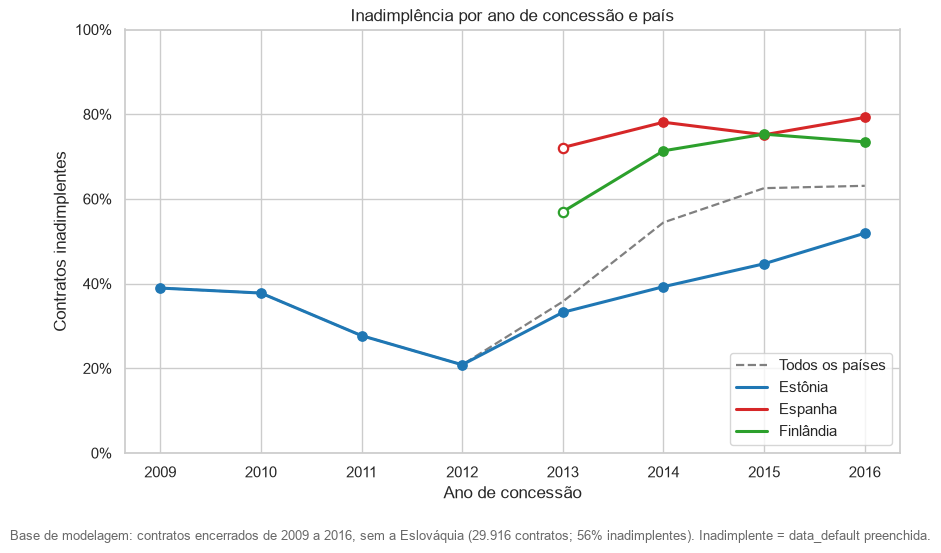

Inadimplência (%) por ano e país:


pais,EE,ES,FI
ano,,,
2009,39.0,NaN,NaN
2010,38.0,NaN,NaN
2011,28.0,NaN,NaN
2012,21.0,NaN,NaN
2013,33.0,72.0,57.0
2014,39.0,78.0,71.0
2015,45.0,75.0,75.0
2016,52.0,79.0,73.0


In [10]:
d = (vw.groupby(['ano', 'pais'])
       .agg(n=('inadimplente', 'size'), taxa=('inadimplente', 'mean')).reset_index())
d['taxa'] *= 100
geral = vw.groupby('ano')['inadimplente'].mean() * 100

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(geral.index, geral.values, color='gray', ls='--', lw=1.6, label='Todos os países')
for p in PAISES:
    g = d[d['pais'] == p]
    ax.plot(g['ano'], g['taxa'], color=CORES[p], lw=2.2, label=NOMES[p])
    pouco = g['n'] < 200
    ax.scatter(g.loc[~pouco, 'ano'], g.loc[~pouco, 'taxa'], color=CORES[p], s=45, zorder=3)
    ax.scatter(g.loc[pouco, 'ano'], g.loc[pouco, 'taxa'], facecolors='white',
               edgecolors=CORES[p], s=45, linewidths=1.6, zorder=3)
ax.set(ylim=(0, 100), xlabel='Ano de concessão', ylabel='Contratos inadimplentes',
       title='Inadimplência por ano de concessão e país')
ax.set_xticks(range(2009, 2017))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.legend(loc='lower right', frameon=True)
n_vw = f'{len(vw):,}'.replace(',', '.')
rodape(fig, f'Base de modelagem: contratos encerrados de 2009 a 2016, sem a Eslováquia '
            f'({n_vw} contratos; {vw["inadimplente"].mean()*100:.0f}% inadimplentes). '
            'Inadimplente = data_default preenchida.')
salvar(fig, '01_inadimplencia_por_ano_pais')
plt.show()

print('Inadimplência (%) por ano e país:')
display(d.pivot(index='ano', columns='pais', values='taxa').round(0))

## Figura 2 · Juro por época e por rating

À esquerda, o juro mediano por ano e país (todos os contratos, 2009–2021). À direita, o juro mediano por **rating do Bondora** e ano.
Se o preço seguisse o risco, as linhas do rating estariam bem separadas em todos os anos.
Juros acima de 100% (Espanha e Finlândia, 2016–2018) são legítimos, não erro de dado.

gravado: docs\figuras\02_juros_por_epoca_e_rating.png


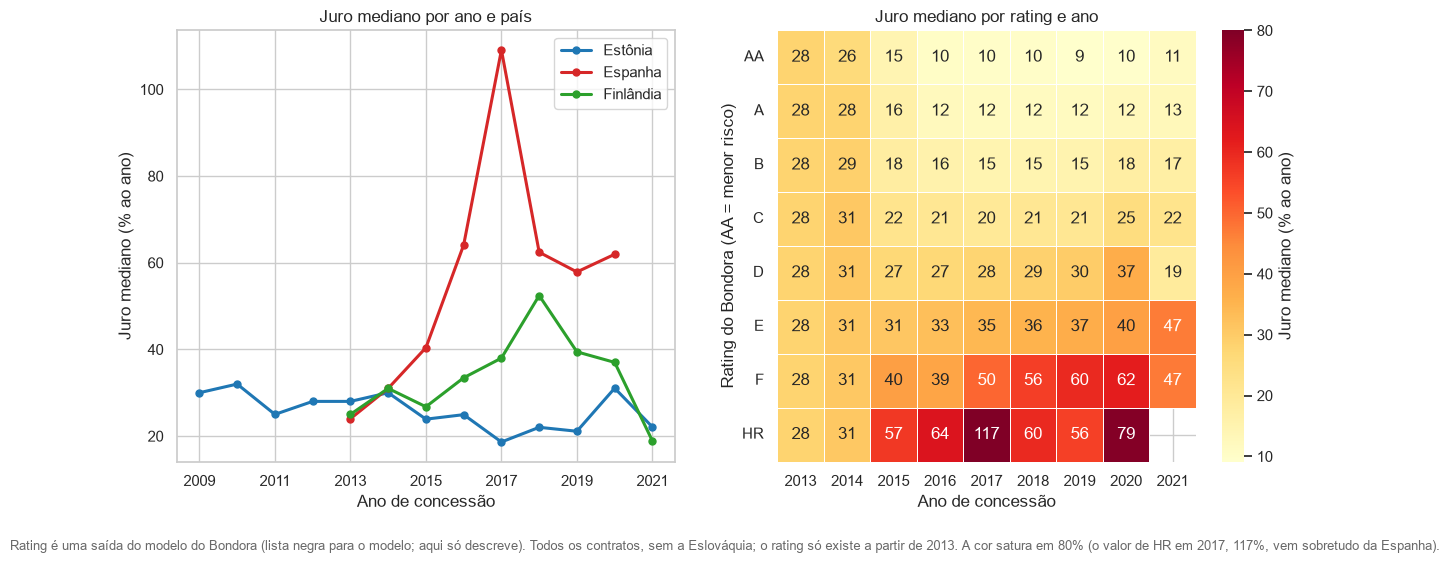

In [11]:
mediana = base.groupby(['ano', 'pais'])['juro_aa'].median().unstack()

ordem = ['AA', 'A', 'B', 'C', 'D', 'E', 'F', 'HR']
r = base[base['rating'].isin(ordem) & base['ano'].between(2013, 2021)]
por_rating = r.groupby(['rating', 'ano'])['juro_aa'].median().unstack().reindex(ordem)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.6), gridspec_kw={'width_ratios': [1, 1.05]})
for p in PAISES:
    ax1.plot(mediana.index, mediana[p], color=CORES[p], lw=2.2, marker='o', ms=5, label=NOMES[p])
ax1.set(xlabel='Ano de concessão', ylabel='Juro mediano (% ao ano)', title='Juro mediano por ano e país')
ax1.set_xticks(range(2009, 2022, 2))
ax1.legend(frameon=True)

sns.heatmap(por_rating, annot=True, fmt='.0f', cmap='YlOrRd', vmax=80, linewidths=0.5, ax=ax2,
            cbar_kws={'label': 'Juro mediano (% ao ano)'})
ax2.set(xlabel='Ano de concessão', ylabel='Rating do Bondora (AA = menor risco)',
        title='Juro mediano por rating e ano')
ax2.tick_params(axis='y', rotation=0)
rodape(fig, 'Rating é uma saída do modelo do Bondora (lista negra para o modelo; aqui só descreve). '
            'Todos os contratos, sem a Eslováquia; o rating só existe a partir de 2013. '
            'A cor satura em 80% (o valor de HR em 2017, 117%, vem sobretudo da Espanha).')
salvar(fig, '02_juros_por_epoca_e_rating')
plt.show()

## Figura 3 · Renda por país

Só contratos com renda maior que zero. **2009 e 2010 ficam fora do gráfico**: a renda mediana desses anos é 11.000, contra cerca de 800 em 2011,
e o mesmo salto aparece em `passivos_total`. A mudança coincide com a adoção do euro na Estônia (01/01/2011): a hipótese é que esses valores estejam em coroas estonianas.
O dicionário do Bondora precisa confirmar.

Estônia · renda mediana e razão renda/valor concedido (mediana), por ano:


,n,renda_mediana,renda_sobre_valor
ano,,,
2009,665,11000.0,61.7
2010,1123,11000.0,48.1
2011,442,800.0,1.0
2012,440,807.0,0.7
2013,2284,796.5,0.4


gravado: docs\figuras\03_renda_por_pais.png


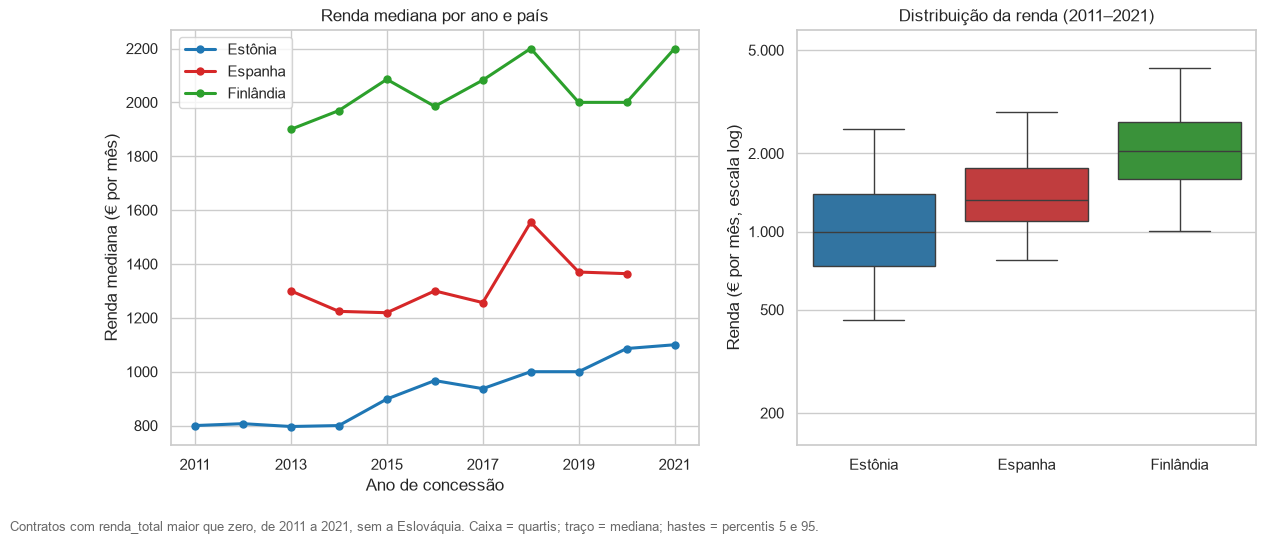

In [12]:
rend = base[base['renda_total'] > 0]
ee = rend[rend['pais'] == 'EE']
print('Estônia · renda mediana e razão renda/valor concedido (mediana), por ano:')
display(ee[ee['ano'] <= 2013].groupby('ano').agg(
    n=('renda_total', 'size'), renda_mediana=('renda_total', 'median'),
    renda_sobre_valor=('renda_total', lambda s: (s / ee.loc[s.index, 'valor_concedido']).median())).round(1))

r2 = rend[rend['ano'] >= 2011]
mediana_renda = r2.groupby(['ano', 'pais'])['renda_total'].median().unstack()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={'width_ratios': [1.15, 1]})
for p in PAISES:
    ax1.plot(mediana_renda.index, mediana_renda[p], color=CORES[p], lw=2.2, marker='o', ms=5, label=NOMES[p])
ax1.set(xlabel='Ano de concessão', ylabel='Renda mediana (€ por mês)', title='Renda mediana por ano e país')
ax1.set_xticks(range(2011, 2022, 2))
ax1.legend(frameon=True)

sns.boxplot(data=r2, x='pais', y='renda_total', order=PAISES, hue='pais', palette=CORES,
            legend=False, showfliers=False, whis=(5, 95), ax=ax2)
ax2.set_yscale('log')
ax2.set_ylim(150, 6000)
ax2.set_yticks([200, 500, 1000, 2000, 5000])
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.')))
ax2.minorticks_off()
ax2.set_xticks(range(3))
ax2.set_xticklabels([NOMES[p] for p in PAISES])
ax2.set(xlabel='', ylabel='Renda (€ por mês, escala log)', title='Distribuição da renda (2011–2021)')
rodape(fig, 'Contratos com renda_total maior que zero, de 2011 a 2021, sem a Eslováquia. '
            'Caixa = quartis; traço = mediana; hastes = percentis 5 e 95.')
salvar(fig, '03_renda_por_pais')
plt.show()

## Figura 4 · O juro cobrado acompanha o default realizado?

Dentro de cada país, os contratos da base de modelagem são divididos em cinco grupos pelo juro cobrado (Q1 = os 20% mais baratos).
O rótulo embaixo é o juro mediano do grupo. É uma leitura descritiva: o risco depende de muitas coisas além do juro.

gravado: docs\figuras\04_juro_cobrado_x_inadimplencia.png


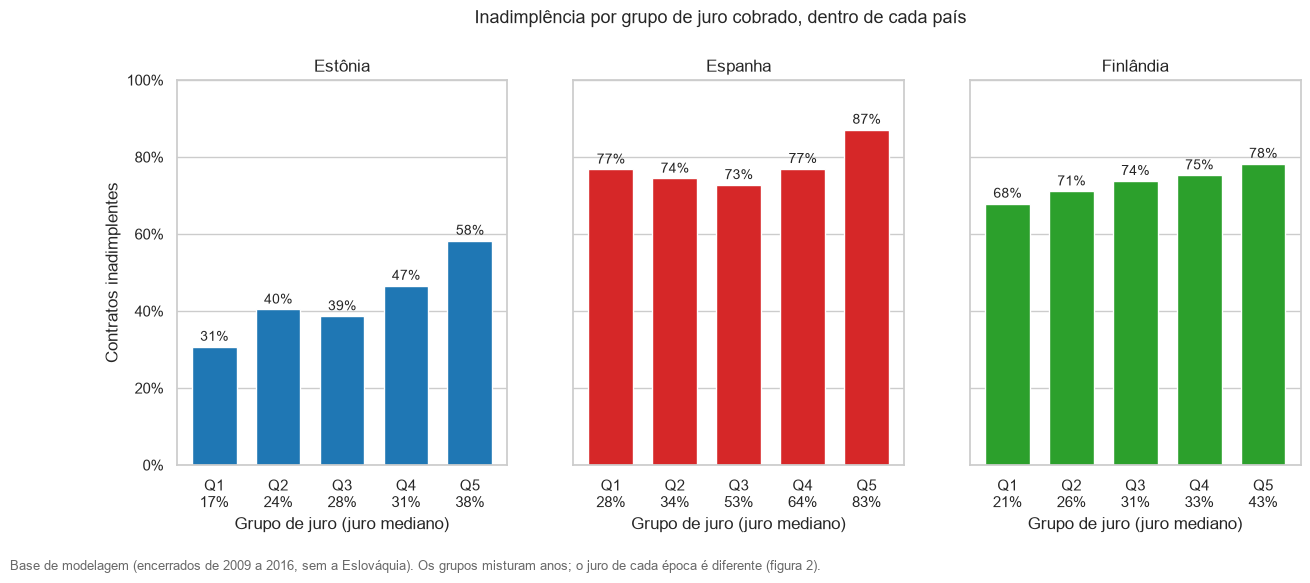

pais,EE,ES,FI
quintil,,,
1,31.0,77.0,68.0
2,40.0,74.0,71.0
3,39.0,73.0,74.0
4,47.0,77.0,75.0
5,58.0,87.0,78.0


In [13]:
q = vw.merge(emp[['loan_id', 'juro_aa']], on='loan_id')
q = q[q['pais'].isin(PAISES)].copy()
q['quintil'] = q.groupby('pais')['juro_aa'].transform(
    lambda s: pd.qcut(s, 5, labels=False, duplicates='drop')) + 1
res = (q.groupby(['pais', 'quintil'])
         .agg(default=('inadimplente', 'mean'), juro=('juro_aa', 'median'), n=('juro_aa', 'size'))
         .reset_index())

fig, axes = plt.subplots(1, 3, figsize=(14.5, 5), sharey=True)
for ax, p in zip(axes, PAISES):
    g = res[res['pais'] == p]
    ax.bar(g['quintil'], g['default'] * 100, color=CORES[p], width=0.7)
    for x, y in zip(g['quintil'], g['default'] * 100):
        ax.text(x, y + 1.5, f'{y:.0f}%', ha='center', fontsize=10)
    ax.set_xticks(g['quintil'])
    ax.set_xticklabels([f'Q{int(k)}\n{j:.0f}%' for k, j in zip(g['quintil'], g['juro'])])
    ax.set(title=NOMES[p], xlabel='Grupo de juro (juro mediano)', ylim=(0, 100))
    ax.grid(axis='x', visible=False)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
axes[0].set_ylabel('Contratos inadimplentes')
fig.suptitle('Inadimplência por grupo de juro cobrado, dentro de cada país', y=1.02, fontsize=13)
rodape(fig, 'Base de modelagem (encerrados de 2009 a 2016, sem a Eslováquia). '
            'Os grupos misturam anos; o juro de cada época é diferente (figura 2).', y=-0.08)
salvar(fig, '04_juro_cobrado_x_inadimplencia')
plt.show()

display(res.pivot(index='quintil', columns='pais', values='default').mul(100).round(0))

## Figura 5 · Gênero: um achado de governança

Proporção de mulheres entre os contratos com gênero informado (0 ou 1). Uma queda abrupta que depois volta ao nível anterior indica
**problema de codificação**, não mudança da clientela: 5.633 clientes aparecem com os dois gêneros em contratos diferentes, e a idade deles é coerente,
ou seja, é a mesma pessoa. O dicionário do Bondora não confirma a causa. Gênero fica fora do treino e do teste do modelo.

gravado: docs\figuras\05_genero_codificacao_por_ano.png


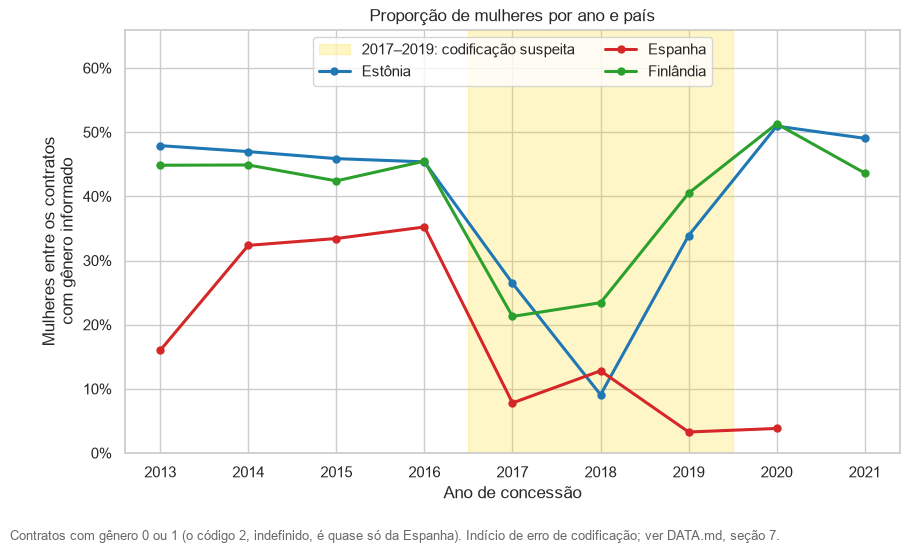

pais,EE,ES,FI
ano,,,
2013,48.0,16.0,45.0
2014,47.0,32.0,45.0
2015,46.0,33.0,42.0
2016,45.0,35.0,45.0
2017,26.0,8.0,21.0
2018,9.0,13.0,23.0
2019,34.0,3.0,41.0
2020,51.0,4.0,51.0
2021,49.0,NaN,44.0


In [14]:
gen = base[base['genero'].isin([0, 1]) & base['ano'].between(2013, 2021)]
mulheres = gen.groupby(['ano', 'pais'])['genero'].mean().unstack() * 100

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axvspan(2016.5, 2019.5, color='gold', alpha=0.22, label='2017–2019: codificação suspeita')
for p in PAISES:
    ax.plot(mulheres.index, mulheres[p], color=CORES[p], lw=2.2, marker='o', ms=5, label=NOMES[p])
ax.set(ylim=(0, 66), xlabel='Ano de concessão', ylabel='Mulheres entre os contratos\ncom gênero informado',
       title='Proporção de mulheres por ano e país')
ax.set_xticks(range(2013, 2022))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.legend(loc='upper center', ncol=2, frameon=True)
rodape(fig, 'Contratos com gênero 0 ou 1 (o código 2, indefinido, é quase só da Espanha). '
            'Indício de erro de codificação; ver DATA.md, seção 7.')
salvar(fig, '05_genero_codificacao_por_ano')
plt.show()

display(mulheres.round(0))

## Leituras

*(com os dados de 03/11/2026; reescreva se o banco for recarregado)*

1. **Inadimplência:** na Estônia sobe de 21% (2012) para 52% (2016). Espanha e Finlândia entram em 2013 com 72% e 57% e chegam a 79% e 73% em 2016. No conjunto, 56%.
2. **Juro por época:** até 2014 o juro mediano é quase igual em todos os ratings (28% a 31%); a partir de 2015 passa a acompanhar o rating (por exemplo, AA 10% a HR 64% em 2016).
   Na Espanha, o juro mediano sobe de 24% (2013) para 109% (2017). Auditar preço entre épocas exige olhar a época.
3. **Renda:** a Finlândia tem a maior (cerca de 2.000 por mês), depois a Espanha (cerca de 1.300) e a Estônia (800 a 1.100). Em 2009–2010 a renda parece estar em outra unidade (hipótese: coroas estonianas).
4. **Juro e default:** na Estônia, o default cresce com o grupo de juro (31% no Q1 e 58% no Q5). Na Espanha e na Finlândia, o juro cobrado varia bastante e o default varia pouco (73% a 87% e 68% a 78%).
5. **Gênero:** a proporção de mulheres na Estônia vai de 45% (2016) para 9% (2018) e volta a 51% (2020).

---

## Testes

*(com os dados de 03/11/2026; refaça se o banco for recarregado)*

1. **Teste conversão moeda:** Teste para ver se houve problema na conversão de moeda quando a Estônia adotou o Euro em 01 de janeiro de 2011. A taxa fixa de conversão da Coroa Estoniana para o Euro é de 15,6466.

In [15]:
hist = tabelas['historico_credito']
x = (emp[['loan_id', 'data_emprestimo', 'valor_solicitado']]
     .merge(cli[['loan_id', 'pais', 'renda_total']], on='loan_id')
     .merge(hist[['loan_id', 'passivos_total']], on='loan_id'))
x = x[x['pais'] == 'EE'].copy()
x['mes'] = x['data_emprestimo'].dt.to_period('M')

# Teste 1: o salto acontece exatamente em 01/2011?
t = x[(x['mes'] >= pd.Period('2010-09')) & (x['mes'] <= pd.Period('2011-04'))].groupby('mes').agg(
    renda=('renda_total', lambda s: s[s > 0].median()),
    passivos=('passivos_total', lambda s: s[s > 0].median()),
    valor_pedido=('valor_solicitado', 'median'))
display(t.round(0))

# Teste 2: o valor pedido x 15,6466 é um número redondo de coroas?
def redondo_em_coroas(s):
    k = s.dropna() * 15.6466
    return ((k - (k / 50).round() * 50).abs() < 0.35).mean()
print(f"até 2010: {redondo_em_coroas(x[x['data_emprestimo'] < '2011-01-01']['valor_solicitado']):.0%}")
print(f"2011 em diante: {redondo_em_coroas(x[x['data_emprestimo'] >= '2011-01-01']['valor_solicitado']):.0%}")

,renda,passivos,valor_pedido
mes,,,
2010-09,10400.0,2236.0,383.0
2010-10,11250.0,2728.0,639.0
2010-11,12400.0,3216.0,511.0
2010-12,12000.0,3075.0,636.0
2011-01,860.0,192.0,830.0
2011-02,720.0,237.0,500.0
2011-03,740.0,230.0,965.0
2011-04,851.0,202.0,850.0


até 2010: 100%
2011 em diante: 0%


## Leituras

*(com os dados de 03/11/2026; reescreva se o banco for recarregado)*

- **Teste 1 (O salto temporal):** Observando a tabela, os valores de renda e passivos despencam de dezembro de 2010 para janeiro de 2011. A renda, por exemplo, cai de 12.000,0 em 2010-12 para apenas 860,0 em 2011-01. Isso comprova visualmente que os dados anteriores a 2011 estavam em Coroas Estonianas (que têm valores nominais muito maiores) e passaram a ser registrados em Euros (divididos por ~15,6).   
- **Teste 2 (A prova da moeda):** O resultado no final da imagem mostra "até 2010: 100%" e "2011 em diante: 0%". Isso significa que 100% dos empréstimos pedidos antes de 2011, se multiplicados pela taxa de 15,6466, resultam em números redondos (múltiplos de 50). A partir de 2011, essa proporção cai para 0%, provando definitivamente que até o final de 2010 os clientes pediam os empréstimos em Coroas, e a partir de 2011 passaram a pedir diretamente em Euros. 